# Chest X Ray Classification: Implementation Platform

This notebook reproduces the main result of the first parent paper and runs the released code of the second parent paper.

* **Parent paper 1:** Aljuaid et al. (2026), *An experimental comparison of deep learning models for pneumonia classification from chest X ray images*, Biomedical Signal Processing and Control. Six pretrained networks, the same 6,939 image dataset, an 80 and 20 split, and 5 fold cross validation.
* **Parent paper 2:** Bassi and Attux (2022), *Covid 19 detection using chest X rays: is lung segmentation important for generalization?*, Research on Biomedical Engineering. A lung segmentation network placed before the classifier. Code and weights: https://github.com/PedroRASB/COVID-19-detection-with-lung-segmentation


**Structure.** The pipeline is a small package, `xray_platform`, written by the cells below. Each module covers one stage, so a stage can be replaced without touching the others:

| Module | Stage |
|---|---|
| `data.py` | listing, loading, and splitting the images |
| `models.py` | pretrained backbones, their input scaling, and classifier heads |
| `train.py` | training on frozen features and two stage fine tuning |
| `evaluate.py` | metrics, tables, and figures |
| `lungs.py` | lung maps from the second parent paper |

## 1. Setup

In [ ]:
# Removes files from earlier runs so every run starts clean. The dataset zip file is kept to avoid a second download.
%cd /content
!rm -rf covid_pneumonia_dataset covid_pneumonia_dataset_wrapped pyimagesearch-covid19-image-classification lung_data xray_platform
#!rm -f covid_pneumonia_dataset.zip

/content


In [ ]:
# Clones the project repository, which holds lung_focus.py, the script that runs the second parent paper's lung finder.
REPO = "/content/pyimagesearch-covid19-image-classification"
!git clone -q https://github.com/MarzSaod/pyimagesearch-covid19-image-classification {REPO}
!ls {REPO}

build_covid_dataset.py	models			 Readme.md
dataset			notebook_images		 report_utils.py
lung_focus.py		original-keras-covid-19  sample_kaggle_dataset.py
model_performance	predict_covid19.py	 train_covid19.py


In [ ]:
# Downloads the dataset (Asraf and Islam, Mendeley Data, version 2) and extracts it into a fresh folder.
import os, shutil, zipfile
%cd /content
ZIP = "covid_pneumonia_dataset.zip"
if not (os.path.exists(ZIP) and zipfile.is_zipfile(ZIP)):
    !wget -q -O {ZIP} "https://data.mendeley.com/public-api/zip/mxc6vb7svm/download/2"
shutil.rmtree("covid_pneumonia_dataset", ignore_errors=True)
with zipfile.ZipFile(ZIP) as z:
    z.extractall("covid_pneumonia_dataset")
for item in os.listdir("covid_pneumonia_dataset"):
    if item.endswith(".zip"):
        inner = os.path.join("covid_pneumonia_dataset", item)
        with zipfile.ZipFile(inner) as z:
            z.extractall("covid_pneumonia_dataset")
        os.remove(inner)

DATASET = "/content/covid_pneumonia_dataset_wrapped/all"
shutil.rmtree(DATASET, ignore_errors=True)
os.makedirs(DATASET)
for c in ["covid", "normal", "pneumonia"]:
    shutil.copytree(f"/content/covid_pneumonia_dataset/{c}", f"{DATASET}/{c}")
print("Dataset folder:", DATASET)

/content
Dataset folder: /content/covid_pneumonia_dataset_wrapped/all


In [ ]:
# Confirms that a GPU is available.
import tensorflow as tf, torch
print("TensorFlow", tf.__version__, "| GPUs:", len(tf.config.list_physical_devices("GPU")))
print("PyTorch", torch.__version__, "| CUDA:", torch.cuda.is_available())
for g in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError:
        pass

TensorFlow 2.21.0 | GPUs: 1
PyTorch 2.14.1+cu130 | CUDA: True


In [ ]:
# Settings for the whole run. The split follows the first parent paper: 5 fold cross validation, so each fold
# tests on 20 percent of the images. Ten percent of each training part is held out to choose the best epoch.
CONFIG = dict(
    classes=["covid", "normal", "pneumonia"],
    image_size=224,
    weights="imagenet",
    folds=5,
    val_frac=0.10,
    seed=42,
    backbones=["VGG16", "VGG19", "ResNet50", "InceptionV3", "DenseNet201"],
    head_epochs=12,
    finetune=dict(backbone="VGG19", unfreeze_prefix="block5", head_epochs=3, tune_epochs=7, fold=0, batch=32),
)

# Values reported by the first parent paper (Table 2 and Table 3).
PARENT_ACCURACY = {"ResNet": 95, "AlexNet": 90, "VGG19": 97, "SqueezeNet": 88, "DenseNet": 92, "InceptionV3": 94}
PARENT_VGG19_BY_CLASS = {"precision": {"pneumonia": 96, "covid": 91, "normal": 99},
                         "recall": {"pneumonia": 98, "covid": 97, "normal": 88},
                         "f1-score": {"pneumonia": 97, "covid": 93, "normal": 94}}
PARENT_VGG19_CONFUSION = [[444, 2, 9], [6, 408, 48], [14, 1, 448]]  # rows: actual normal, pneumonia, covid

## 2. Pipeline modules

In [ ]:
!mkdir -p /content/xray_platform

In [ ]:
%%writefile /content/xray_platform/__init__.py
"""Modular pipeline for three class chest X ray classification (normal, pneumonia, covid)."""

Writing /content/xray_platform/__init__.py


In [ ]:
%%writefile /content/xray_platform/data.py
"""Dataset listing, image loading, and split plans."""
import os
from concurrent.futures import ThreadPoolExecutor

import cv2
import numpy as np
import pandas as pd

IMAGE_EXTS = (".png", ".jpg", ".jpeg", ".jfif", ".bmp")


def list_images(root, classes):
    """Lists images in root/<class>/ (top level only), sorted by class then file name."""
    paths, labels = [], []
    for ci, c in enumerate(classes):
        folder = os.path.join(root, c)
        names = sorted(n for n in os.listdir(folder) if n.lower().endswith(IMAGE_EXTS))
        paths += [os.path.join(folder, n) for n in names]
        labels += [ci] * len(names)
    return np.array(paths), np.array(labels)


def count_table(paths, labels, classes):
    exts = pd.Series([os.path.splitext(p)[1].lower() for p in paths])
    t = pd.crosstab(exts.rename("file type"), pd.Series([classes[l] for l in labels], name="class"))
    t.loc["total"] = t.sum()
    return t


def read_rgb(path, size):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        from PIL import Image
        img = np.array(Image.open(path).convert("RGB"))
    else:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)


def load_images(paths, size, workers=8):
    """Loads every image as uint8 RGB at size x size."""
    out = np.zeros((len(paths), size, size, 3), np.uint8)
    with ThreadPoolExecutor(workers) as ex:
        for i, img in enumerate(ex.map(lambda p: read_rgb(p, size), paths)):
            out[i] = img
    return out


def kfold_plan(labels, k, val_frac, seed):
    """Stratified k fold plan. Each fold tests on 1/k of the data and keeps val_frac of the rest for validation."""
    from sklearn.model_selection import StratifiedKFold, train_test_split

    folds = []
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    for f, (trval, test) in enumerate(skf.split(np.zeros(len(labels)), labels)):
        tr, va = train_test_split(trval, test_size=val_frac, stratify=labels[trval], random_state=seed + f)
        folds.append((np.sort(tr), np.sort(va), np.sort(test)))
    return folds


def plan_table(folds, labels, classes):
    rows = []
    for f, parts in enumerate(folds):
        for name, ix in zip(("train", "validation", "test"), parts):
            row = {"fold": f + 1, "set": name, "images": len(ix)}
            row.update({c: int((labels[ix] == i).sum()) for i, c in enumerate(classes)})
            rows.append(row)
    return pd.DataFrame(rows).set_index(["fold", "set"])


def file_properties(paths):
    """Properties of each file that say nothing about the lungs: file type, original width and height, color mode, and file size."""
    from PIL import Image

    def one(p):
        with Image.open(p) as im:
            w, h, mode = im.size[0], im.size[1], im.mode
        return {"type": os.path.splitext(p)[1].lower(), "width": w, "height": h, "mode": mode, "kilobytes": os.path.getsize(p) / 1024}

    with ThreadPoolExecutor(16) as ex:
        table = pd.DataFrame(list(ex.map(one, paths)))
    return table


def encode_properties(table):
    """Turns the property table into numbers for a classifier."""
    return pd.get_dummies(table, columns=["type", "mode"], dtype=float).to_numpy(np.float32)

Writing /content/xray_platform/data.py


In [ ]:
%%writefile /content/xray_platform/models.py
"""Pretrained backbones, their own input scaling, and classifier builders."""
import numpy as np

BACKBONES = {
    "VGG16": ("VGG16", "vgg16"),
    "VGG19": ("VGG19", "vgg19"),
    "ResNet50": ("ResNet50", "resnet50"),
    "InceptionV3": ("InceptionV3", "inception_v3"),
    "DenseNet201": ("DenseNet201", "densenet"),
}
PREDICT_BATCH = {"DenseNet201": 8, "InceptionV3": 16}


def backbone(name, size, weights="imagenet"):
    from tensorflow.keras import applications
    cls_name, _ = BACKBONES[name]
    return getattr(applications, cls_name)(weights=weights, include_top=False, input_shape=(size, size, 3))


def preprocess(name, x):
    """Applies the pixel scaling the backbone was trained with. x is float32 with values 0 to 255."""
    import importlib
    module = importlib.import_module("tensorflow.keras.applications." + BACKBONES[name][1])
    return module.preprocess_input(np.array(x, dtype=np.float32, copy=True))


def extract_features(name, images, size, weights="imagenet", chunk=256):
    """Global average pooled features from a frozen backbone, one row per image."""
    from tensorflow.keras import Model, layers
    base = backbone(name, size, weights)
    feat = Model(base.input, layers.GlobalAveragePooling2D()(base.output))
    out = []
    for s in range(0, len(images), chunk):
        x = preprocess(name, images[s:s + chunk])
        out.append(feat.predict(x, batch_size=PREDICT_BATCH.get(name, 32), verbose=0))
    del feat, base
    release()
    return np.concatenate(out).astype(np.float32)


def release():
    """Frees memory held by finished models."""
    import gc
    from tensorflow import keras
    keras.backend.clear_session()
    gc.collect()


def head(input_dim, n_classes, hidden=64, dropout=0.5):
    """Small classifier trained on top of frozen features."""
    from tensorflow import keras
    return keras.Sequential([
        keras.Input((input_dim,)),
        keras.layers.Dense(hidden, activation="relu"),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(n_classes, activation="softmax"),
    ])


def finetune_model(name, size, n_classes, unfreeze_prefix, weights="imagenet", hidden=256, dropout=0.5):
    """Backbone with augmentation, its own scaling, and a new head. Layers whose names start with unfreeze_prefix stay trainable."""
    import importlib
    from tensorflow import keras

    base = backbone(name, size, weights)
    base.trainable = True
    for layer in base.layers:
        layer.trainable = bool(unfreeze_prefix) and layer.name.startswith(unfreeze_prefix)
    module = importlib.import_module("tensorflow.keras.applications." + BACKBONES[name][1])

    augment = keras.Sequential([
        keras.layers.RandomFlip("horizontal"),
        keras.layers.RandomRotation(15 / 360),
        keras.layers.RandomTranslation(0.1, 0.1),
        keras.layers.RandomZoom(0.1),
        keras.layers.RandomContrast(0.1),
    ], name="augment")

    inp = keras.Input((size, size, 3))
    x = augment(inp)
    x = keras.layers.Lambda(lambda t: module.preprocess_input(t), name="scaling")(x)
    x = base(x, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dense(hidden, activation="relu")(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inp, out), base

Writing /content/xray_platform/models.py


In [ ]:
%%writefile /content/xray_platform/train.py
"""Training routines. Each returns test probabilities so evaluation stays separate."""
import time

import numpy as np


def fit_head(feats, labels, plan, n_classes, seed, epochs=12, batch=32, lr=1e-3):
    """Trains the small head on one fold and keeps the epoch with the best validation accuracy."""
    from tensorflow import keras
    from .models import head

    tr, va, te = plan
    keras.utils.set_random_seed(seed)
    model = head(feats.shape[1], n_classes)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    stop = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=epochs, restore_best_weights=True)
    model.fit(feats[tr], labels[tr], validation_data=(feats[va], labels[va]), epochs=epochs, batch_size=batch,
              callbacks=[stop], verbose=0)
    return model.predict(feats[te], verbose=0)


def cross_validate(feats, labels, folds, n_classes, seed=0, **kw):
    """Runs fit_head on every fold. Returns a list of (test indices, probabilities)."""
    return [(plan[2], fit_head(feats, labels, plan, n_classes, seed + f, **kw)) for f, plan in enumerate(folds)]


def fine_tune(name, images, labels, plan, size, n_classes, seed, unfreeze_prefix, head_epochs, tune_epochs,
              batch=32, head_lr=1e-3, tune_lr=1e-4, weights="imagenet"):
    """Two stage fine tuning: first the new head with the backbone frozen, then the last block together with the head."""
    from tensorflow import keras
    from .models import finetune_model

    tr, va, te = plan
    keras.utils.set_random_seed(seed)
    model, base = finetune_model(name, size, n_classes, unfreeze_prefix, weights)
    history = {"accuracy": [], "val_accuracy": [], "loss": [], "val_loss": []}

    def run(epochs, lr, base_trainable):
        for layer in base.layers:
            layer.trainable = base_trainable and layer.name.startswith(unfreeze_prefix)
        model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        stop = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=epochs, restore_best_weights=True)
        h = model.fit(images[tr], labels[tr], validation_data=(images[va], labels[va]), epochs=epochs,
                      batch_size=batch, callbacks=[stop], verbose=2)
        for k in history:
            history[k] += h.history.get(k, [])

    t0 = time.time()
    run(head_epochs, head_lr, False)
    if tune_epochs:
        run(tune_epochs, tune_lr, True)
    probs = model.predict(images[te], batch_size=batch, verbose=0)
    return te, probs, history, time.time() - t0


def cross_validate_tree(feats, labels, folds, seed=0, max_depth=6):
    """Decision tree on every fold, trained on train plus validation. Used for the baseline that never sees the picture."""
    from sklearn.tree import DecisionTreeClassifier
    out = []
    for f, (tr, va, te) in enumerate(folds):
        fit_ix = np.concatenate([tr, va])
        tree = DecisionTreeClassifier(max_depth=max_depth, random_state=seed + f).fit(feats[fit_ix], labels[fit_ix])
        out.append((te, tree.predict_proba(feats[te])))
    return out

Writing /content/xray_platform/train.py


In [ ]:
%%writefile /content/xray_platform/evaluate.py
"""Metrics, tables, and figures. Kept apart from training so either side can be replaced."""
import numpy as np
import pandas as pd


def fold_metrics(labels, results, n_classes):
    """Accuracy, macro F1, and macro AUC for each fold."""
    from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
    rows = []
    for te, p in results:
        y, pred = labels[te], p.argmax(1)
        rows.append({"accuracy": accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro"),
                     "macro_auc": roc_auc_score(y, p, multi_class="ovr")})
    return pd.DataFrame(rows)


def pooled(labels, results):
    """Joins the test folds back into one prediction for every image."""
    te = np.concatenate([r[0] for r in results])
    p = np.concatenate([r[1] for r in results])
    return labels[te], p


def class_report(labels, results, classes):
    from sklearn.metrics import classification_report
    y, p = pooled(labels, results)
    rep = classification_report(y, p.argmax(1), target_names=classes, output_dict=True, zero_division=0)
    return (pd.DataFrame(rep).T.loc[classes, ["precision", "recall", "f1-score", "support"]] * [100, 100, 100, 1]).round(1)


def mean_sd(series, scale=100, digits=1):
    s = pd.Series(series)
    return f"{s.mean() * scale:.{digits}f} ± {s.std(ddof=1) * scale:.{digits}f}" if len(s) > 1 else f"{s.mean() * scale:.{digits}f}"


def confusion_accuracy(matrix):
    m = np.asarray(matrix)
    return float(np.trace(m) / m.sum())


def confusion_report(matrix, row_names):
    """Precision, recall, and F1 implied by a published confusion matrix (rows are actual classes, columns are predicted)."""
    m = np.asarray(matrix, dtype=float)
    tp = np.diag(m)
    precision, recall = tp / m.sum(0), tp / m.sum(1)
    f1 = 2 * precision * recall / (precision + recall)
    return (pd.DataFrame({"precision": precision, "recall": recall, "f1-score": f1}, index=row_names) * 100).round(1)


def plot_confusion(labels, results, classes, title, ax=None):
    import matplotlib.pyplot as plt
    from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
    y, p = pooled(labels, results)
    cm = confusion_matrix(y, p.argmax(1))
    if ax is None:
        _, ax = plt.subplots(figsize=(4.2, 4))
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(title, fontsize=10)
    return cm


def plot_history(history, title):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
    for ax, key in zip(axes, ("accuracy", "loss")):
        ax.plot(history[key], label="train")
        ax.plot(history["val_" + key], label="validation")
        ax.set_xlabel("epoch")
        ax.set_title(f"{title}: {key}", fontsize=10)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def show_samples(images, labels, classes, per_class=4, seed=0):
    import matplotlib.pyplot as plt
    rng = np.random.RandomState(seed)
    fig, axes = plt.subplots(len(classes), per_class, figsize=(2.2 * per_class, 2.3 * len(classes)))
    for r, _ in enumerate(classes):
        pick = rng.choice(np.where(labels == r)[0], per_class, replace=False)
        for c, i in enumerate(pick):
            axes[r, c].imshow(images[i])
            axes[r, c].axis("off")
        axes[r, 0].set_title(classes[r], fontsize=10, loc="left")
    plt.tight_layout()
    plt.show()

Writing /content/xray_platform/evaluate.py


In [ ]:
%%writefile /content/xray_platform/lungs.py
"""Second parent paper (Bassi and Attux, 2022): their released lung segmentation network, run on this dataset."""
import os

import numpy as np


def load_masks(masks_npz, dataset_root, paths):
    """Returns one 0 to 1 lung map per image, in the same order as paths."""
    z = np.load(masks_npz)
    rel = [str(r) for r in z["rel"]]
    index = {os.path.normpath(os.path.join(dataset_root, r)): i for i, r in enumerate(rel)}
    by_name = {(os.path.basename(os.path.dirname(os.path.join(dataset_root, r))), os.path.basename(r)): i for i, r in enumerate(rel)}
    order = []
    for p in paths:
        key = os.path.normpath(p)
        order.append(index[key] if key in index else by_name[(os.path.basename(os.path.dirname(p)), os.path.basename(p))])
    return z["mask"][order].astype(np.float32) / 255.0


def lungs_only(images, masks):
    """Multiplies each image by its lung map, the input used by the second parent paper."""
    import cv2
    size = images.shape[1]
    out = np.empty_like(images)
    for i in range(len(images)):
        m = masks[i] if masks[i].shape[0] == size else cv2.resize(masks[i], (size, size))
        out[i] = (images[i] * m[..., None]).astype(np.uint8)
    return out

Writing /content/xray_platform/lungs.py


In [ ]:
import sys, importlib, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
sys.path.insert(0, "/content")
import xray_platform
from xray_platform import data, models, train, evaluate, lungs
for m in (data, models, train, evaluate, lungs):
    importlib.reload(m)

## 3. Data

In [ ]:
# Lists every image and checks the class counts against the dataset page (2,313 images per class).
CLASSES = CONFIG["classes"]
paths, labels = data.list_images(DATASET, CLASSES)
display(data.count_table(paths, labels, CLASSES))
assert all((labels == i).sum() == 2313 for i in range(len(CLASSES))), "Unexpected class counts."

class,covid,normal,pneumonia
file type,,,
.jfif,37,0,0
.jpeg,218,336,2137
.jpg,1725,0,0
.png,333,1977,176
total,2313,2313,2313


Loaded 6939 images in 100 seconds, array shape (6939, 224, 224, 3).


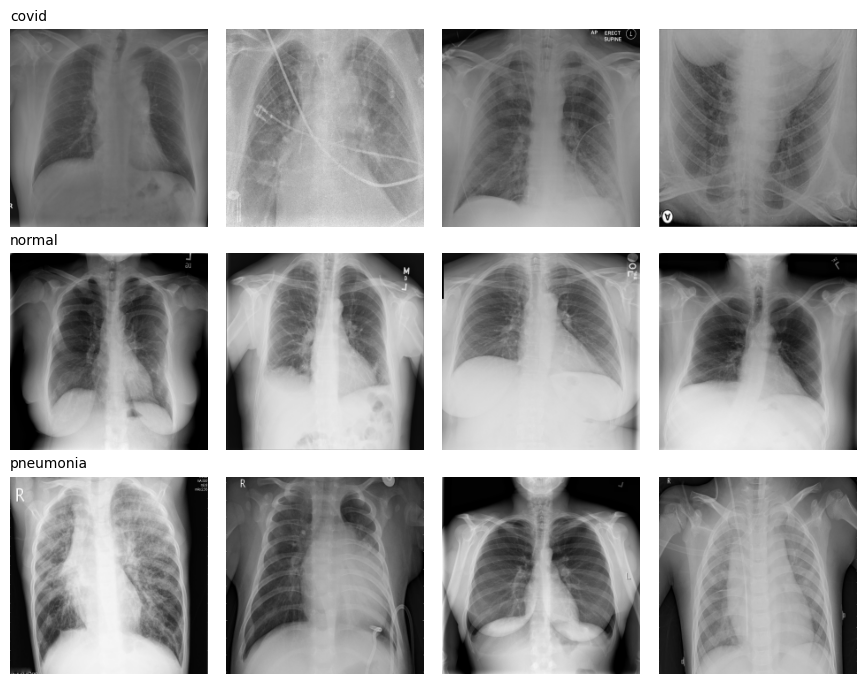

In [ ]:
# Loads all images into memory at 224 by 224 pixels and shows a few examples.
t0 = time.time()
images = data.load_images(paths, CONFIG["image_size"])
print(f"Loaded {len(images)} images in {time.time() - t0:.0f} seconds, array shape {images.shape}.")
evaluate.show_samples(images, labels, CLASSES)

In [ ]:
# Builds the 5 fold plan shared by every model, so all models are tested on exactly the same images.
folds = data.kfold_plan(labels, CONFIG["folds"], CONFIG["val_frac"], CONFIG["seed"])
display(data.plan_table(folds, labels, CLASSES).head(3))

images  covid  normal  pneumonia
fold set                                         
1    train         4995   1665    1665       1665
     validation     556    185     185        186
     test          1388    463     463        462

## 4. Parent paper 2: lung segmentation network

`lung_focus.py` downloads the authors' released model definition (`StackedNet.py`) and trained weights (`SegmentationDNN.pt`) from their GitHub repository, checks both files against fixed SHA256 fingerprints, and produces a lung map for every image.

/content/pyimagesearch-covid19-image-classification
[INFO] device: cuda
[INFO] 6939 images in 3 classes: ['covid', 'normal', 'pneumonia']
[INFO] downloading StackedNet.py ...
[INFO] StackedNet.py verified
[INFO] downloading SegmentationDNN.pt ...
[INFO] SegmentationDNN.pt verified
[INFO] lung finder: 96/6939 images, 51.8 images per second, about 2.2 minutes left
[INFO] lung finder: 640/6939 images, 78.1 images per second, about 1.3 minutes left
[INFO] lung finder: 1280/6939 images, 81.5 images per second, about 1.2 minutes left
[INFO] lung finder: 1920/6939 images, 82.5 images per second, about 1.0 minutes left
[INFO] lung finder: 2560/6939 images, 82.9 images per second, about 0.9 minutes left
[INFO] lung finder: 3200/6939 images, 83.1 images per second, about 0.8 minutes left
[INFO] lung finder: 3840/6939 images, 83.1 images per second, about 0.6 minutes left
[INFO] lung finder: 4480/6939 images, 83.0 images per second, about 0.5 minutes left
[INFO] lung finder: 5120/6939 images, 82.

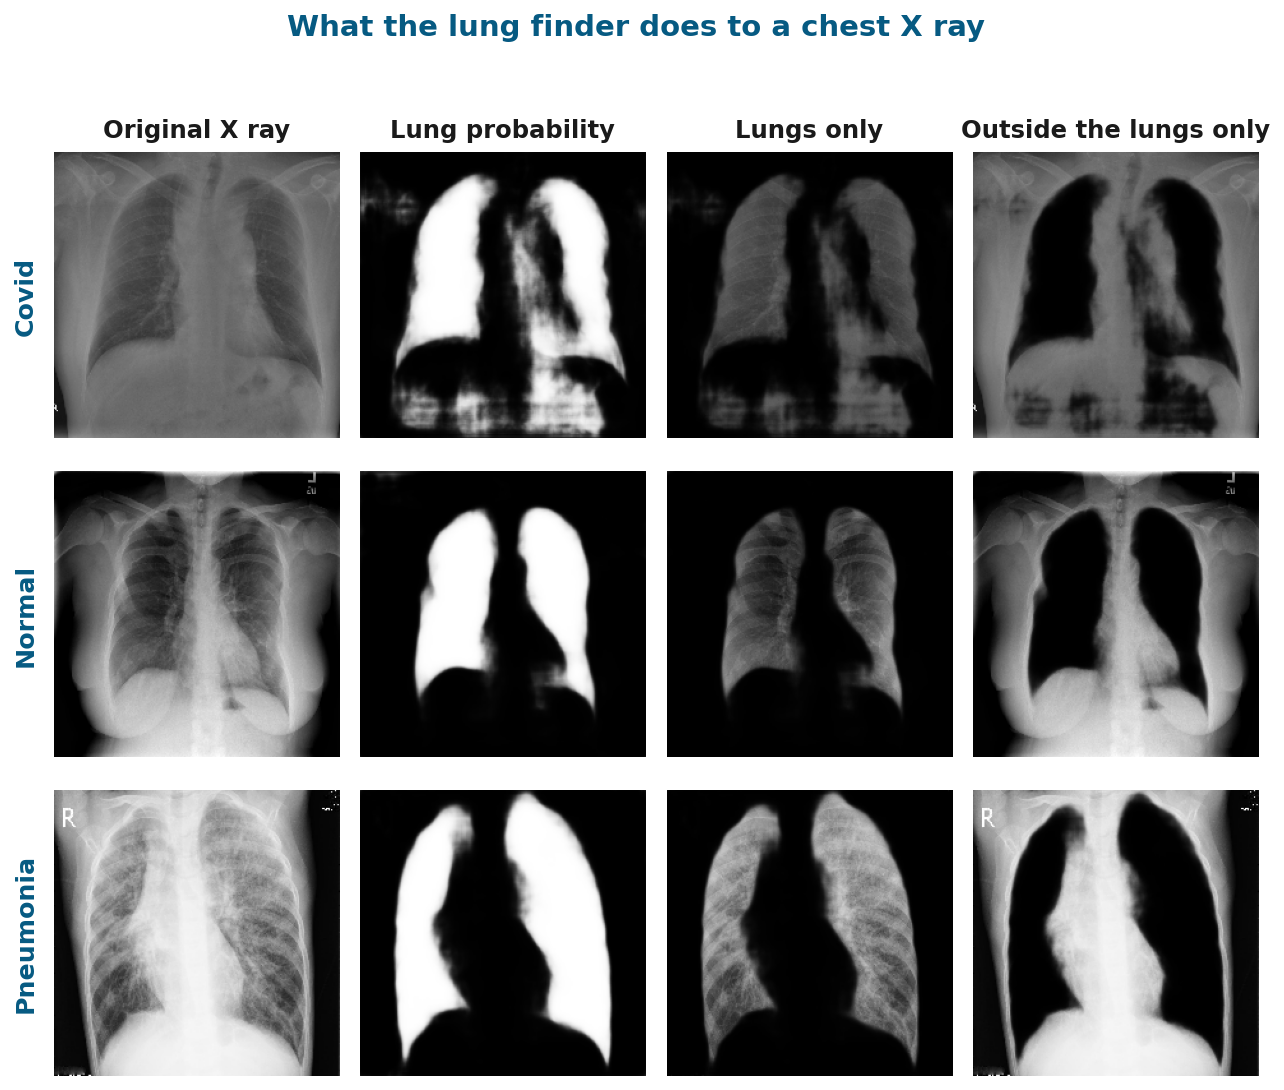

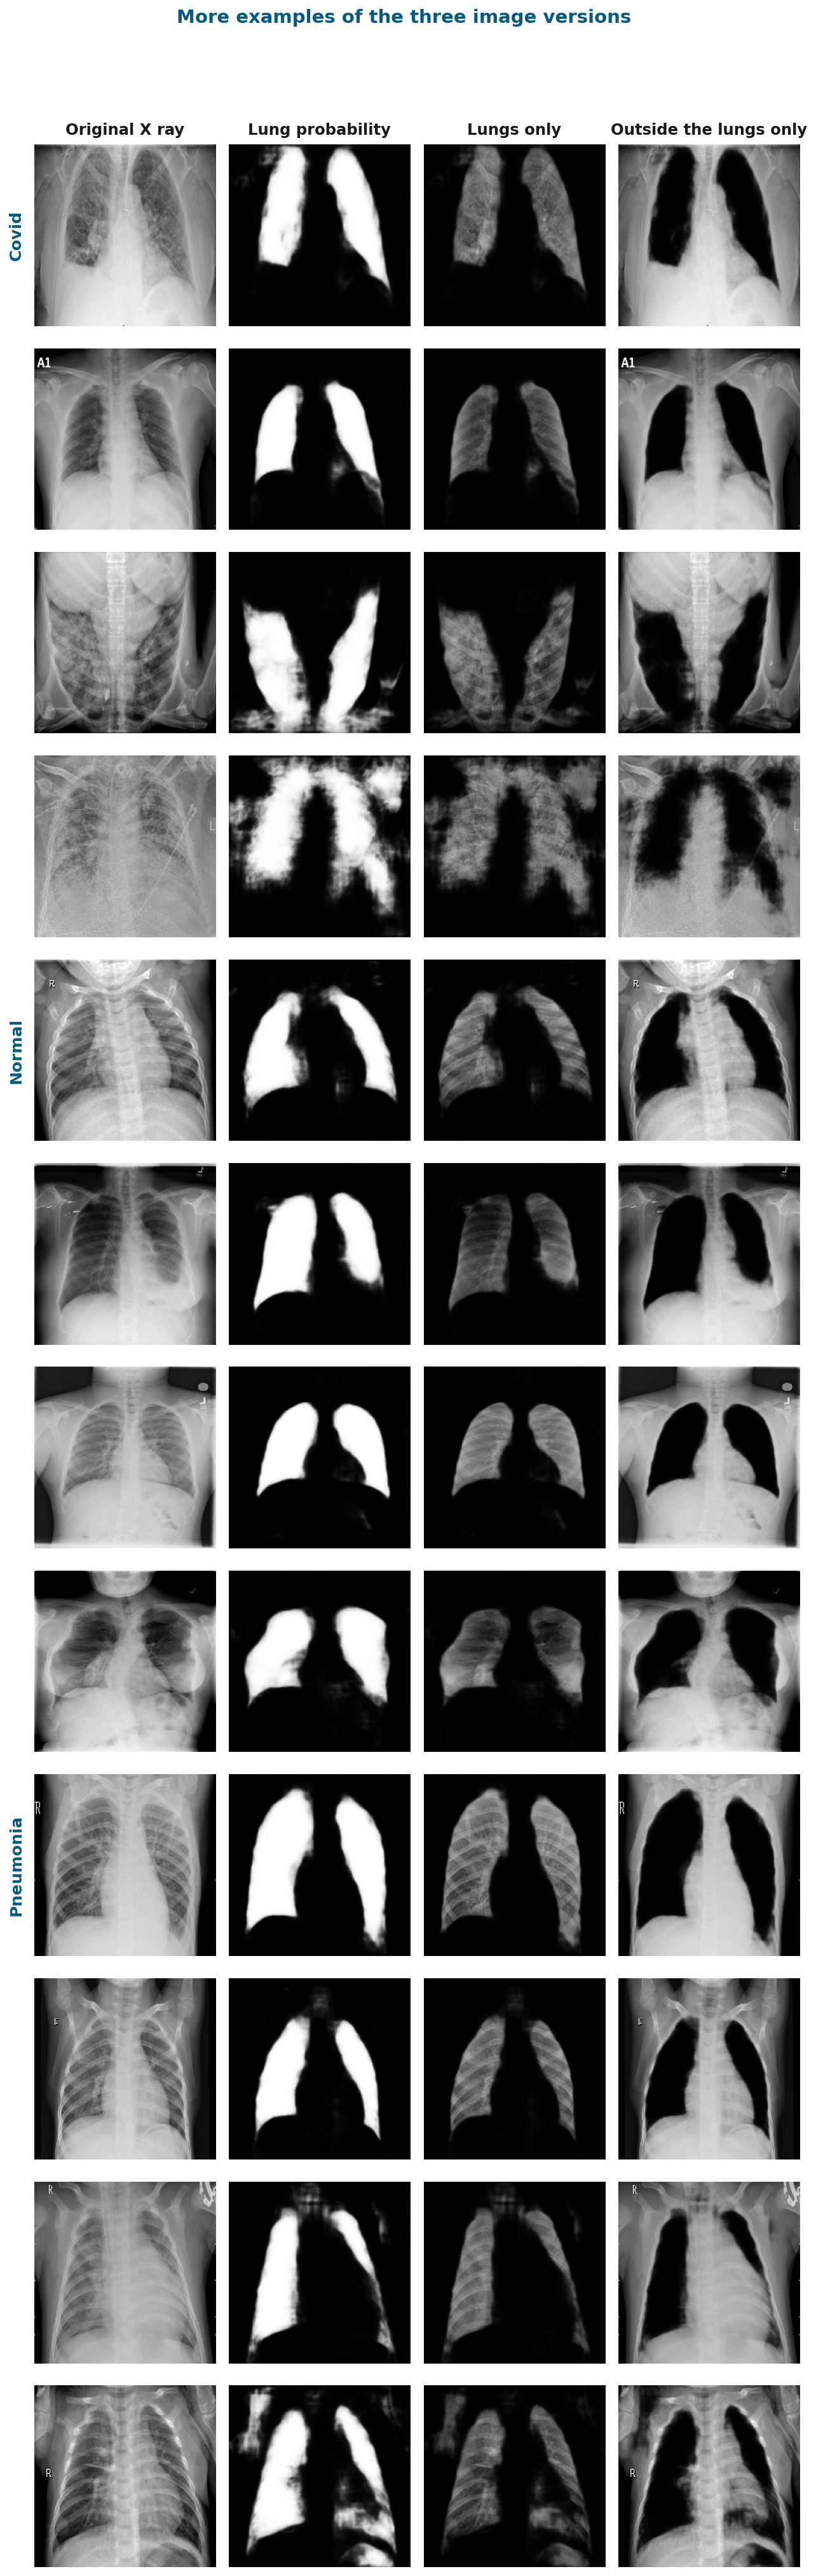

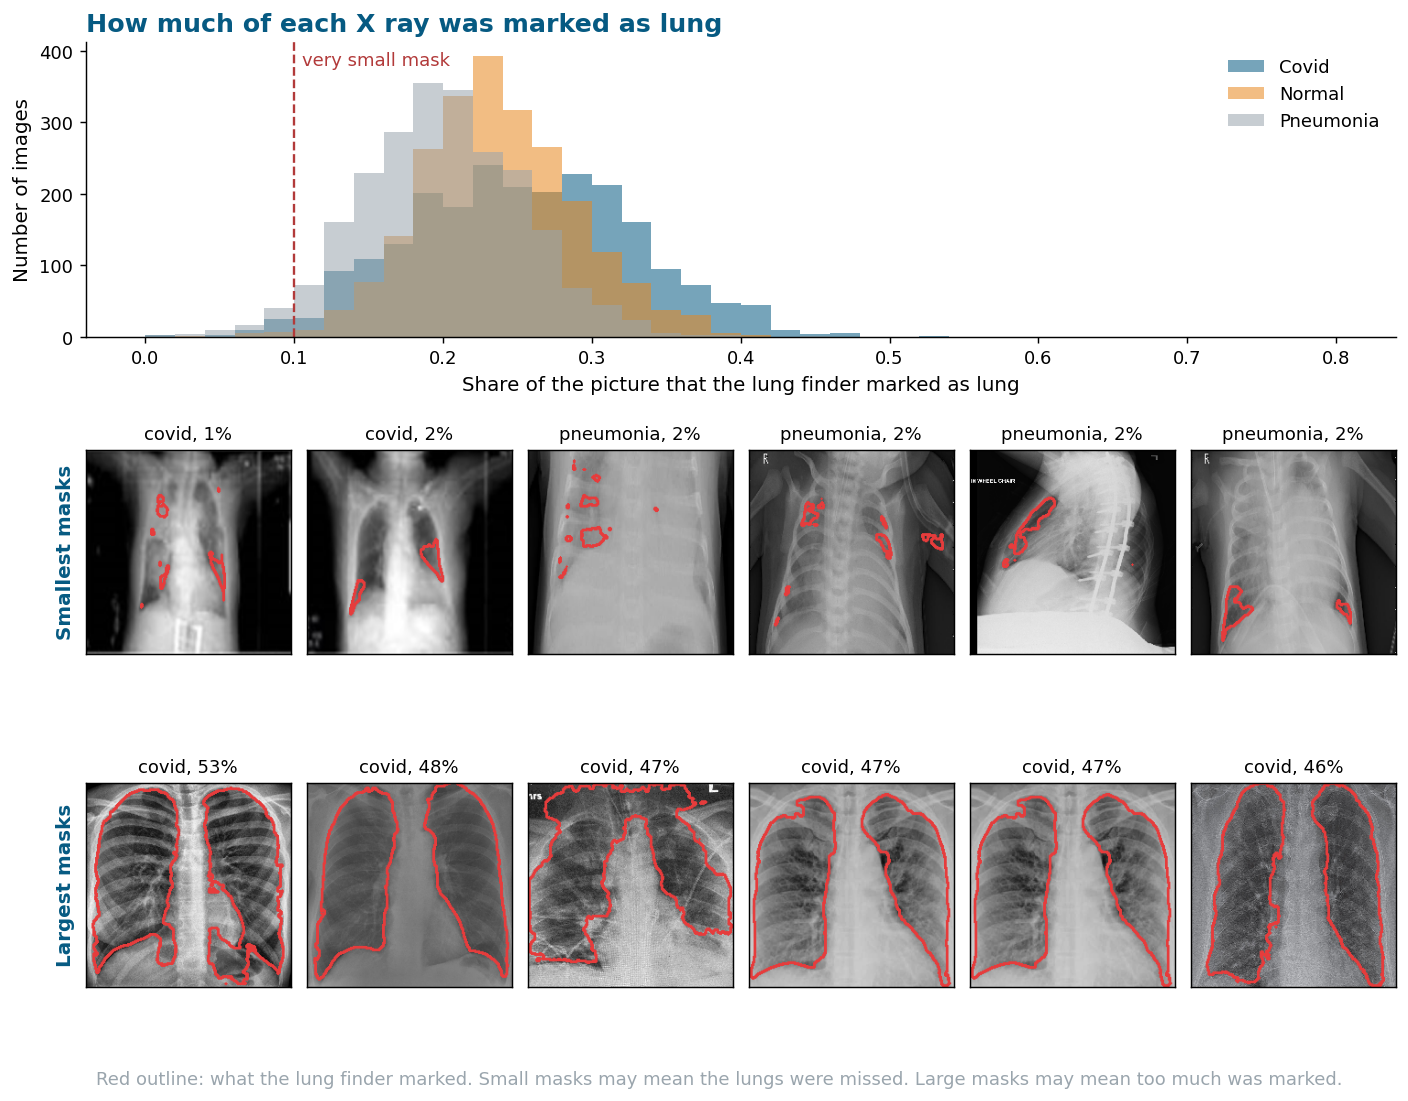

In [ ]:
LUNG_DIR = "/content/lung_data"
%cd {REPO}
!python lung_focus.py --dataset {DATASET} --outdir {LUNG_DIR}
%cd /content
assert os.path.exists(f"{LUNG_DIR}/masks.npz"), "The lung finder did not finish. Read the messages printed above."
for name in ["lung_focus_preview.png", "lung_focus_more.png", "lung_focus_quality.png"]:
    if os.path.exists(f"{LUNG_DIR}/{name}"):
        display(Image(f"{LUNG_DIR}/{name}"))

Average share of the picture covered by the lungs: 23%


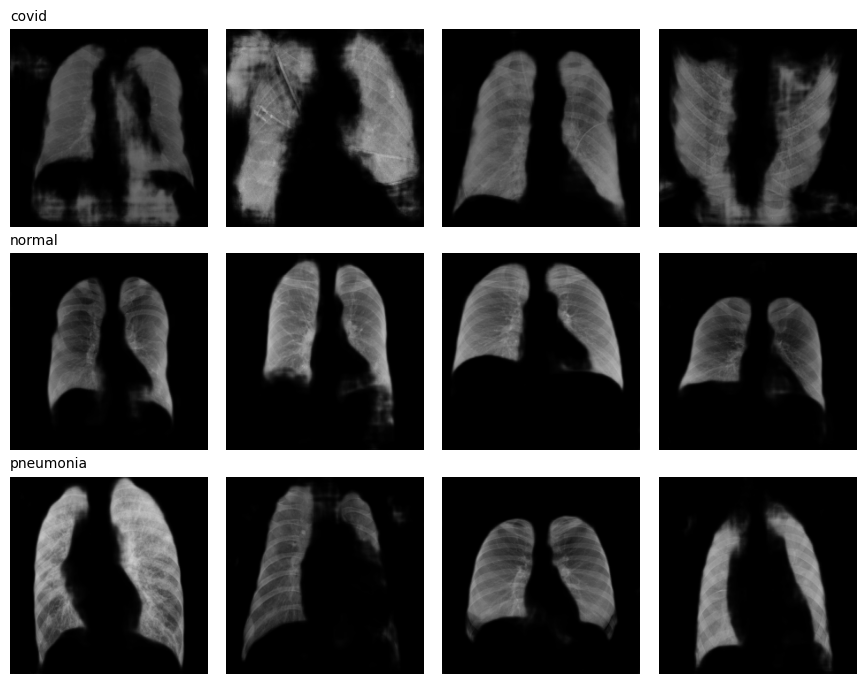

In [ ]:
# Builds the lungs only version of every image (image multiplied by its lung map), as in the second parent paper.
masks = lungs.load_masks(f"{LUNG_DIR}/masks.npz", DATASET, paths)
images_lungs = lungs.lungs_only(images, masks)
print("Average share of the picture covered by the lungs:", f"{(masks > 0.5).mean():.0%}")
evaluate.show_samples(images_lungs, labels, CLASSES)

## 5. Parent paper 1: five pretrained networks

Each pretrained network reads every image once with its own input scaling. A small classifier (Dense 64, Dropout 0.5, softmax) is then trained on the saved features in every fold. AlexNet and SqueezeNet are not part of Keras Applications, so VGG16 is included as a fifth network.

In [ ]:
# Feature extraction for every backbone, plus DenseNet201 on the lungs only images for the second parent paper.
features = {}
t0 = time.time()
for name in CONFIG["backbones"]:
    features[name] = models.extract_features(name, images, CONFIG["image_size"], CONFIG["weights"])
    print(f"{name}: {features[name].shape}, {time.time() - t0:.0f} seconds so far")
features["DenseNet201, lungs only"] = models.extract_features("DenseNet201", images_lungs, CONFIG["image_size"], CONFIG["weights"])
print(f"DenseNet201, lungs only: done, {time.time() - t0:.0f} seconds in total")

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG16: (6939, 512), 85 seconds so far
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG19: (6939, 512), 145 seconds so far
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50: (6939, 2048), 211 seconds so far
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
InceptionV3: (6939, 2048), 318 seconds so far
74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
DenseNet201: (6939, 1920), 541 seconds so far
DenseNet201, lungs only: done, 668 seconds in total


In [ ]:
# Trains and tests the classifier on all 5 folds for every feature set.
results, metrics = {}, {}
t0 = time.time()
for name, f in features.items():
    results[name] = train.cross_validate(f, labels, folds, len(CLASSES), seed=CONFIG["seed"], epochs=CONFIG["head_epochs"])
    metrics[name] = evaluate.fold_metrics(labels, results[name], len(CLASSES))
    print(f"{name}: {evaluate.mean_sd(metrics[name].accuracy)} percent accuracy, {time.time() - t0:.0f} seconds so far")

VGG16: 94.5 ± 0.4 percent accuracy, 57 seconds so far
VGG19: 94.3 ± 0.5 percent accuracy, 110 seconds so far
ResNet50: 94.7 ± 0.3 percent accuracy, 164 seconds so far
InceptionV3: 90.4 ± 0.6 percent accuracy, 218 seconds so far
DenseNet201: 94.6 ± 0.8 percent accuracy, 272 seconds so far
DenseNet201, lungs only: 90.6 ± 0.7 percent accuracy, 325 seconds so far


In [ ]:
# Compares the 5 fold results with the accuracies reported by the first parent paper.
match = {"VGG16": None, "VGG19": "VGG19", "ResNet50": "ResNet", "InceptionV3": "InceptionV3", "DenseNet201": "DenseNet"}
rows = []
for name in CONFIG["backbones"]:
    m = metrics[name]
    rows.append({"network": name,
                 "parent paper accuracy (%)": PARENT_ACCURACY.get(match[name], "not tested"),
                 "accuracy here (%)": evaluate.mean_sd(m.accuracy),
                 "macro F1 (%)": evaluate.mean_sd(m.macro_f1),
                 "macro AUC": evaluate.mean_sd(m.macro_auc, scale=1, digits=3)})
display(pd.DataFrame(rows).set_index("network"))
print("Accuracy implied by the parent paper's own VGG19 confusion matrix (Table 3):",
      f"{evaluate.confusion_accuracy(PARENT_VGG19_CONFUSION):.1%}")

,parent paper accuracy (%),accuracy here (%),macro F1 (%),macro AUC
network,,,,
VGG16,not tested,94.5 ± 0.4,94.5 ± 0.4,0.988 ± 0.003
VGG19,97,94.3 ± 0.5,94.3 ± 0.5,0.988 ± 0.001
ResNet50,95,94.7 ± 0.3,94.7 ± 0.2,0.989 ± 0.001
InceptionV3,94,90.4 ± 0.6,90.4 ± 0.6,0.978 ± 0.001
DenseNet201,92,94.6 ± 0.8,94.6 ± 0.8,0.989 ± 0.002


Accuracy implied by the parent paper's own VGG19 confusion matrix (Table 3): 94.2%


precision


,here,"parent paper, text","parent paper, from its confusion matrix"
covid,96.9,91,88.7
normal,88.7,99,95.7
pneumonia,98.0,96,99.3


recall


,here,"parent paper, text","parent paper, from its confusion matrix"
covid,96.0,97,96.8
normal,96.2,88,97.6
pneumonia,90.6,98,88.3


f1-score


,here,"parent paper, text","parent paper, from its confusion matrix"
covid,96.5,93,92.6
normal,92.3,94,96.6
pneumonia,94.2,97,93.5


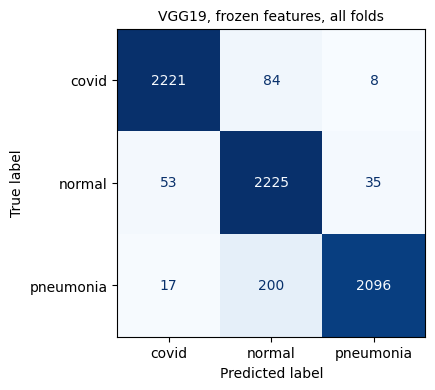

In [ ]:
# Per class results for VGG19 with all folds pooled, next to the values the parent paper reports in its text
# and the values its own Table 3 confusion matrix implies.
ours = evaluate.class_report(labels, results["VGG19"], CLASSES)
parent = pd.DataFrame(PARENT_VGG19_BY_CLASS).loc[CLASSES]
implied = evaluate.confusion_report(PARENT_VGG19_CONFUSION, ["normal", "pneumonia", "covid"]).loc[CLASSES]
for metric in ["precision", "recall", "f1-score"]:
    print(metric)
    display(pd.DataFrame({"here": ours[metric], "parent paper, text": parent[metric],
                          "parent paper, from its confusion matrix": implied[metric]}))
fig, ax = plt.subplots(figsize=(4.2, 4))
evaluate.plot_confusion(labels, results["VGG19"], CLASSES, "VGG19, frozen features, all folds", ax=ax)
plt.show()

## 6. Parent paper 2: full image against lungs only

Same classifier and folds, with DenseNet201 (the classifier used by the second parent paper) on the full image and on the lungs only image.

In [ ]:
comp = pd.DataFrame({name: {"accuracy (%)": evaluate.mean_sd(metrics[name].accuracy),
                            "macro F1 (%)": evaluate.mean_sd(metrics[name].macro_f1),
                            "macro AUC": evaluate.mean_sd(metrics[name].macro_auc, scale=1, digits=3)}
                     for name in ["DenseNet201", "DenseNet201, lungs only"]}).T
display(comp)
display(evaluate.class_report(labels, results["DenseNet201, lungs only"], CLASSES))

,accuracy (%),macro F1 (%),macro AUC
DenseNet201,94.6 ± 0.8,94.6 ± 0.8,0.989 ± 0.002
"DenseNet201, lungs only",90.6 ± 0.7,90.7 ± 0.7,0.977 ± 0.003


,precision,recall,f1-score,support
covid,93.3,91.8,92.5,2313.0
normal,85.1,91.1,88.0,2313.0
pneumonia,94.1,89.0,91.5,2313.0


## 7. Baseline that never sees the picture

A decision tree trained only on file properties (file type, original width and height, color mode, and file size) on the same 5 folds. A score close to the networks above means the file properties alone already separate most of the classes.

In [ ]:
props = data.file_properties(paths)
display(pd.crosstab((props["type"] + ", " + props["width"].astype(str) + " pixels wide").rename("file type and width"), pd.Series([CLASSES[l] for l in labels], name="class")).sort_values("normal", ascending=False).head(8))
results["file properties only"] = train.cross_validate_tree(data.encode_properties(props), labels, folds, seed=CONFIG["seed"])
metrics["file properties only"] = evaluate.fold_metrics(labels, results["file properties only"], len(CLASSES))
display(pd.DataFrame({n: {"accuracy (%)": evaluate.mean_sd(metrics[n].accuracy), "macro AUC": evaluate.mean_sd(metrics[n].macro_auc, 1, 3)}
                      for n in ["file properties only", "VGG19", "DenseNet201"]}).T)
display(evaluate.class_report(labels, results["file properties only"], CLASSES))

class,covid,normal,pneumonia
file type and width,,,
".png, 1024 pixels wide",2,1977,176
".jpeg, 1608 pixels wide",0,7,7
".jpeg, 1442 pixels wide",0,5,1
".jpeg, 1570 pixels wide",0,4,0
".jpeg, 1774 pixels wide",0,4,0
".jpeg, 1550 pixels wide",0,4,0
".jpeg, 1496 pixels wide",0,4,5
".jpeg, 1422 pixels wide",0,4,2


,accuracy (%),macro AUC
file properties only,96.3 ± 0.4,0.982 ± 0.003
VGG19,94.3 ± 0.5,0.988 ± 0.001
DenseNet201,94.6 ± 0.8,0.989 ± 0.002


,precision,recall,f1-score,support
covid,99.0,98.2,98.6,2313.0
normal,92.0,99.2,95.5,2313.0
pneumonia,98.5,91.5,94.9,2313.0


## 8. Parent paper 1: fine tuning VGG19

The first parent paper fine tuned its networks with heavy augmentation and the Adam optimizer at a learning rate of 0.001. The version here augments with flips, rotations up to 15 degrees, shifts, zoom, and contrast changes. VGG19 first trains a new head with the backbone frozen, then trains its last convolution block together with the head at a learning rate of 0.0001. This is the slowest cell and runs on one fold.

Epoch 1/3
157/157 - 45s - 289ms/step - accuracy: 0.8418 - loss: 0.4820 - val_accuracy: 0.8453 - val_loss: 0.5075
Epoch 2/3
157/157 - 27s - 170ms/step - accuracy: 0.8871 - loss: 0.3339 - val_accuracy: 0.9101 - val_loss: 0.3119
Epoch 3/3
157/157 - 28s - 175ms/step - accuracy: 0.8981 - loss: 0.3084 - val_accuracy: 0.9173 - val_loss: 0.2620
Epoch 1/7
157/157 - 38s - 242ms/step - accuracy: 0.8967 - loss: 0.3100 - val_accuracy: 0.8327 - val_loss: 0.7462
Epoch 2/7
157/157 - 34s - 216ms/step - accuracy: 0.9219 - loss: 0.2363 - val_accuracy: 0.9460 - val_loss: 0.1820
Epoch 3/7
157/157 - 34s - 217ms/step - accuracy: 0.9381 - loss: 0.1898 - val_accuracy: 0.9371 - val_loss: 0.2471
Epoch 4/7
157/157 - 35s - 223ms/step - accuracy: 0.9465 - loss: 0.1693 - val_accuracy: 0.9568 - val_loss: 0.1875
Epoch 5/7
157/157 - 35s - 225ms/step - accuracy: 0.9548 - loss: 0.1458 - val_accuracy: 0.9514 - val_loss: 0.2644
Epoch 6/7
157/157 - 36s - 228ms/step - accuracy: 0.9540 - loss: 0.1457 - val_accuracy: 0.9299 - 

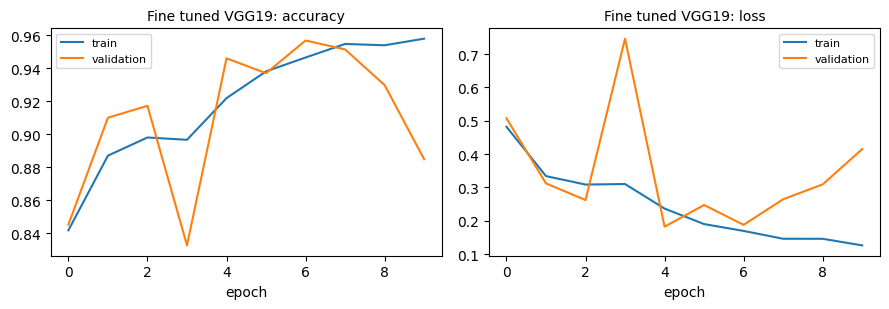

,precision,recall,f1-score,support
covid,98.9,95.7,97.3,463.0
normal,90.2,97.4,93.7,463.0
pneumonia,95.9,91.3,93.6,462.0


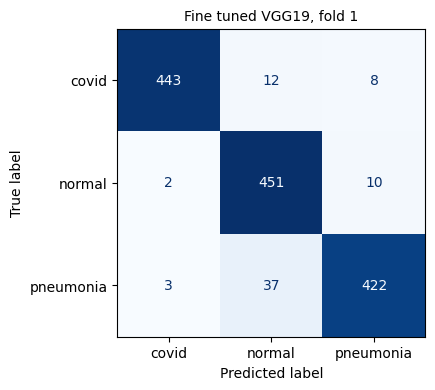

In [ ]:
ft = CONFIG["finetune"]
plan = folds[ft["fold"]]
te, probs, history, seconds = train.fine_tune(ft["backbone"], images, labels, plan, CONFIG["image_size"], len(CLASSES),
                                              CONFIG["seed"], ft["unfreeze_prefix"], ft["head_epochs"], ft["tune_epochs"],
                                              batch=ft["batch"], weights=CONFIG["weights"])
ft_results = [(te, probs)]
ft_metrics = evaluate.fold_metrics(labels, ft_results, len(CLASSES))
print(f"Fine tuned {ft['backbone']} on fold {ft['fold'] + 1}: accuracy {ft_metrics.accuracy[0]:.1%}, "
      f"macro AUC {ft_metrics.macro_auc[0]:.3f}, {seconds / 60:.1f} minutes")
evaluate.plot_history(history, f"Fine tuned {ft['backbone']}")
display(evaluate.class_report(labels, ft_results, CLASSES))
fig, ax = plt.subplots(figsize=(4.2, 4))
evaluate.plot_confusion(labels, ft_results, CLASSES, f"Fine tuned {ft['backbone']}, fold {ft['fold'] + 1}", ax=ax)
plt.show()

## 9. Summary

In [ ]:
summary = [{"model": f"{n}, frozen features, 5 folds", "parent paper (%)": PARENT_ACCURACY.get(match.get(n) or "", "not tested"),
            "accuracy (%)": evaluate.mean_sd(metrics[n].accuracy), "macro AUC": evaluate.mean_sd(metrics[n].macro_auc, 1, 3)}
           for n in CONFIG["backbones"]]
summary.append({"model": "DenseNet201 lungs only, frozen features, 5 folds", "parent paper (%)": "not tested",
                "accuracy (%)": evaluate.mean_sd(metrics["DenseNet201, lungs only"].accuracy),
                "macro AUC": evaluate.mean_sd(metrics["DenseNet201, lungs only"].macro_auc, 1, 3)})
summary.append({"model": "file properties only, decision tree, 5 folds", "parent paper (%)": "not tested",
                "accuracy (%)": evaluate.mean_sd(metrics["file properties only"].accuracy),
                "macro AUC": evaluate.mean_sd(metrics["file properties only"].macro_auc, 1, 3)})
summary.append({"model": f"{ft['backbone']}, fine tuned, fold {ft['fold'] + 1}", "parent paper (%)": PARENT_ACCURACY["VGG19"],
                "accuracy (%)": f"{ft_metrics.accuracy[0] * 100:.1f}", "macro AUC": f"{ft_metrics.macro_auc[0]:.3f}"})
display(pd.DataFrame(summary).set_index("model"))
print("Parent paper VGG19: 97 percent in Table 2, and 94.2 percent from its Table 3 confusion matrix.")

,parent paper (%),accuracy (%),macro AUC
model,,,
"VGG16, frozen features, 5 folds",not tested,94.5 ± 0.4,0.988 ± 0.003
"VGG19, frozen features, 5 folds",97,94.3 ± 0.5,0.988 ± 0.001
"ResNet50, frozen features, 5 folds",95,94.7 ± 0.3,0.989 ± 0.001
"InceptionV3, frozen features, 5 folds",94,90.4 ± 0.6,0.978 ± 0.001
"DenseNet201, frozen features, 5 folds",92,94.6 ± 0.8,0.989 ± 0.002
"DenseNet201 lungs only, frozen features, 5 folds",not tested,90.6 ± 0.7,0.977 ± 0.003
"file properties only, decision tree, 5 folds",not tested,96.3 ± 0.4,0.982 ± 0.003
"VGG19, fine tuned, fold 1",97,94.8,0.993


Parent paper VGG19: 97 percent in Table 2, and 94.2 percent from its Table 3 confusion matrix.
